In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
import sys
import subprocess

print("Python:")
print(sys.version)

print("\nPackages:\n")

for pkg in [
    "diffusers",
    "huggingface-hub",
    "transformers",
    "accelerate",
    "safetensors"
]:
    print("=" * 50)
    print(pkg)

    subprocess.run([
        sys.executable,
        "-m",
        "pip",
        "show",
        pkg
    ])

Python:
3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]

Packages:

diffusers
huggingface-hub
transformers
accelerate
safetensors


In [30]:
# Uninstall existing packages to prevent conflicts
!pip uninstall -y huggingface-hub transformers diffusers accelerate safetensors

# E2-B: ONNX Runtime
!pip install -q -U optimum[onnxruntime] onnxruntime

# Common utilities
!pip install -q ultralytics opencv-python pillow psutil pandas matplotlib

Found existing installation: huggingface_hub 0.36.2
Uninstalling huggingface_hub-0.36.2:
  Successfully uninstalled huggingface_hub-0.36.2
Found existing installation: transformers 4.36.0
Uninstalling transformers-4.36.0:
  Successfully uninstalled transformers-4.36.0
Found existing installation: diffusers 0.30.0
Uninstalling diffusers-0.30.0:
  Successfully uninstalled diffusers-0.30.0
Found existing installation: accelerate 0.21.0
Uninstalling accelerate-0.21.0:
  Successfully uninstalled accelerate-0.21.0
Found existing installation: safetensors 0.4.5
Uninstalling safetensors-0.4.5:
  Successfully uninstalled safetensors-0.4.5
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
peft 0.20.0 requires accelerate>=0.21.0, which is not installed.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [32]:
!pip uninstall -y diffusers transformers peft accelerate optimum optimum-onnx \
    sentence-transformers safetensors huggingface-hub

!pip install -U \
    "diffusers==0.40.0" \
    "transformers>=4.41.2,<6" \
    "accelerate>=1.1.0" \
    "safetensors>=0.8.0" \
    "peft>=0.20.0" \
    "huggingface-hub>=1.16.0,<2.0"

Found existing installation: transformers 4.57.6
Uninstalling transformers-4.57.6:
  Successfully uninstalled transformers-4.57.6
Found existing installation: peft 0.20.0
Uninstalling peft-0.20.0:
  Successfully uninstalled peft-0.20.0
Found existing installation: optimum 2.1.0
Uninstalling optimum-2.1.0:
  Successfully uninstalled optimum-2.1.0
Found existing installation: optimum-onnx 0.1.0
Uninstalling optimum-onnx-0.1.0:
  Successfully uninstalled optimum-onnx-0.1.0
Found existing installation: sentence-transformers 5.7.0
Uninstalling sentence-transformers-5.7.0:
  Successfully uninstalled sentence-transformers-5.7.0
Found existing installation: safetensors 0.8.0
Uninstalling safetensors-0.8.0:
  Successfully uninstalled safetensors-0.8.0
Found existing installation: huggingface_hub 0.36.2
Uninstalling huggingface_hub-0.36.2:
  Successfully uninstalled huggingface_hub-0.36.2
  Using cached diffusers-0.40.0-py3-none-any.whl.metadata (20 kB)
  Using cached transformers-5.17.0-py3-non

In [7]:
!pip install -q git+https://github.com/ChaoningZhang/MobileSAM.git

  Preparing metadata (setup.py) ... done


In [8]:
BASE_DIR = "/content/drive/MyDrive/inter_IIT/Task_2/"
BENCHMARK_DIR = BASE_DIR + "benchmarks/"

In [9]:
import os
import re
import time
import json
import platform
import psutil

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from PIL import Image

from ultralytics import YOLO

print("PyTorch:", torch.__version__)
print("CPU:", platform.processor())
print("Logical CPUs:", os.cpu_count())

PyTorch: 2.11.0+cpu
CPU: x86_64
Logical CPUs: 2


In [10]:
from mobile_sam import (
    sam_model_registry,
    SamAutomaticMaskGenerator,
    SamPredictor
)

/usr/local/lib/python3.13/dist-packages/mobile_sam/modeling/tiny_vit_sam.py:656: UserWarning: Overwriting tiny_vit_5m_224 in registry with mobile_sam.modeling.tiny_vit_sam.tiny_vit_5m_224. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  return register_model(fn_wrapper)
/usr/local/lib/python3.13/dist-packages/mobile_sam/modeling/tiny_vit_sam.py:656: UserWarning: Overwriting tiny_vit_11m_224 in registry with mobile_sam.modeling.tiny_vit_sam.tiny_vit_11m_224. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  return register_model(fn_wrapper)
/usr/local/lib/python3.13/dist-packages/mobile_sam/modeling/tiny_vit_sam.py:656: UserWarning: Overwriting tiny_vit_21m_224 in registry with mobile_sam.modeling.tiny_vit_sam.tiny_vit_21m_224. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  return register_

In [11]:
DEVICE = "cpu"

CPU_THREADS = max(
    1,
    os.cpu_count() // 2
)

cv2.setNumThreads(CPU_THREADS)

print("CPU:", platform.processor())
print("Logical CPU cores:", os.cpu_count())
print("OpenCV threads:", CPU_THREADS)
print("RAM:",
      round(
          psutil.virtual_memory().total / (1024**3),
          2
      ),
      "GB")

CPU: x86_64
Logical CPU cores: 2
OpenCV threads: 1
RAM: 12.67 GB


In [12]:
YOLO_MODEL_NAME = "yolov8n.pt"

yolo_model = YOLO(
    YOLO_MODEL_NAME
)

print("YOLOv8n loaded.")

YOLOv8n loaded.


In [13]:
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-inpainting"

E2_IMAGE_SIZE = 512
E2_NUM_STEPS = 10

GUIDANCE_SCALE = 7.0
STRENGTH = 0.85

SEED = 42

print("Model:", MODEL_ID)
print("Image size:", E2_IMAGE_SIZE)
print("Diffusion steps:", E2_NUM_STEPS)

Model: stable-diffusion-v1-5/stable-diffusion-inpainting
Image size: 512
Diffusion steps: 10


In [14]:
from mobile_sam import sam_model_registry, SamPredictor

MOBILE_SAM_PATH = "mobile_sam.pt"

if not os.path.exists(MOBILE_SAM_PATH):
    !wget -q https://github.com/ChaoningZhang/MobileSAM/raw/master/weights/mobile_sam.pt -O mobile_sam.pt

mobile_sam = sam_model_registry["vit_t"](
    checkpoint=MOBILE_SAM_PATH
)

mobile_sam.to(DEVICE)
mobile_sam.eval()

predictor = SamPredictor(mobile_sam)

print("MobileSAM loaded.")

MobileSAM loaded.


In [15]:
mobile_sam = sam_model_registry[
    "vit_t"
](
    checkpoint=MOBILE_SAM_PATH
)

mobile_sam.to(
    device=DEVICE
)

mobile_sam.eval()

predictor = SamPredictor(
    mobile_sam
)

print("MobileSAM loaded on CPU.")

MobileSAM loaded on CPU.


In [16]:
mobile_sam_size_mb = (
    os.path.getsize(MOBILE_SAM_PATH)
    / (1024 ** 2)
)

mobile_sam_params = sum(
    p.numel()
    for p in mobile_sam.parameters()
)

print(
    f"MobileSAM size: "
    f"{mobile_sam_size_mb:.2f} MB"
)

print(
    f"MobileSAM parameters: "
    f"{mobile_sam_params:,}"
)

print(
    f"MobileSAM parameters: "
    f"{mobile_sam_params / 1e6:.2f} M"
)

MobileSAM size: 38.84 MB
MobileSAM parameters: 10,130,092
MobileSAM parameters: 10.13 M


In [17]:
def normalize_target(target):
    target = target.lower().strip()

    aliases = {
        "bike": "bicycle",
        "bikes": "bicycle",
        "cars": "car",
        "dogs": "dog",
        "people": "person",
        "persons": "person",
        "motorbike": "motorcycle",
        "motorbikes": "motorcycle",
    }

    return aliases.get(target, target)


def parse_instruction(instruction):
    instruction = instruction.lower().strip()

    # Replacement
    match = re.search(
        r"(?:replace|change|turn)\s+(?:the\s+)?(.+?)\s+"
        r"(?:with|into)\s+(?:a\s+|an\s+)?(.+)",
        instruction
    )

    if match:
        source = normalize_target(match.group(1))
        target = match.group(2).strip()

        target = re.sub(
            r"^(a|an|the)\s+",
            "",
            target
        )

        return {
            "action": "replace",
            "source": source,
            "target": target
        }

    # Removal
    match = re.search(
        r"(?:remove|delete|erase|eliminate)\s+"
        r"(?:the\s+|a\s+|an\s+)?(.+)",
        instruction
    )

    if match:
        source = normalize_target(match.group(1))

        return {
            "action": "remove",
            "source": source,
            "target": None
        }

    raise ValueError(
        f"Unsupported instruction: {instruction}"
    )

In [18]:
def find_class_id(model, target):
    target = normalize_target(target)

    names = model.names

    for class_id, name in names.items():
        if name.lower() == target:
            return class_id

    return None

In [19]:
def detect_target(
    image,
    target,
    confidence=0.25,
    imgsz=640
):
    class_id = find_class_id(yolo_model, target)

    if class_id is None:
        raise ValueError(
            f"YOLOv8n does not contain class '{target}'."
        )

    results = yolo_model.predict(
        source=image,
        conf=confidence,
        imgsz=imgsz,
        device="cpu",
        verbose=False
    )

    result = results[0]

    candidates = []

    if result.boxes is None:
        return None

    for box in result.boxes:
        cls = int(box.cls.item())

        if cls != class_id:
            continue

        conf = float(box.conf.item())

        xyxy = box.xyxy[0].cpu().numpy()

        candidates.append({
            "bbox": xyxy.tolist(),
            "confidence": conf
        })

    if not candidates:
        return None

    # Highest-confidence detection
    candidates.sort(
        key=lambda x: x["confidence"],
        reverse=True
    )

    return candidates[0]

In [20]:
def segment_with_mobile_sam(image, bbox):
    """
    image: BGR numpy image
    bbox: [x1, y1, x2, y2]

    returns:
        mask: uint8 {0,255}
        score: MobileSAM confidence
    """

    image_rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    predictor.set_image(image_rgb)

    input_box = np.array(
        bbox,
        dtype=np.float32
    )

    masks, scores, logits = predictor.predict(
        box=input_box,
        multimask_output=True
    )

    best_idx = int(np.argmax(scores))

    mask = masks[best_idx]

    mask = (
        mask.astype(np.uint8) * 255
    )

    score = float(scores[best_idx])

    return mask, score

In [21]:
def prepare_diffusion_mask(
    mask,
    dilation=5,
    blur=2
):
    mask = mask.astype(np.uint8)

    kernel = np.ones(
        (3, 3),
        dtype=np.uint8
    )

    if dilation > 0:

        dilate_kernel = np.ones(
            (3, 3),
            dtype=np.uint8
        )

        mask = cv2.dilate(
            mask,
            dilate_kernel,
            iterations=dilation
        )

    if blur > 0:

        mask = cv2.GaussianBlur(
            mask,
            (0, 0),
            blur
        )

    return mask

In [22]:
import sys
import torch
import diffusers
import transformers
import huggingface_hub

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Diffusers:", diffusers.__version__)
print("Transformers:", transformers.__version__)
print("HF Hub:", huggingface_hub.__version__)

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cpu
Diffusers: 0.40.0
Transformers: 5.17.0
HF Hub: 1.33.0


In [23]:
from diffusers import (
    StableDiffusionInpaintPipeline,
    DPMSolverMultistepScheduler
)

print("Import successful!")

Import successful!


In [24]:
import torch

from diffusers import (
    StableDiffusionInpaintPipeline,
    DPMSolverMultistepScheduler
)

print("Loading E2-A diffusion model...")

pipe_e2a = StableDiffusionInpaintPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float32,
    safety_checker=None,
    requires_safety_checker=False
)

# Faster scheduler
pipe_e2a.scheduler = DPMSolverMultistepScheduler.from_config(
    pipe_e2a.scheduler.config
)

pipe_e2a = pipe_e2a.to("cpu")

pipe_e2a.set_progress_bar_config(
    disable=True
)

print("E2-A loaded.")

Loading E2-A diffusion model...


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


E2-A loaded.


In [25]:
def directory_size_mb(path):
    total = 0

    for root, dirs, files in os.walk(path):
        for file in files:
            fp = os.path.join(root, file)

            if os.path.isfile(fp):
                total += os.path.getsize(fp)

    return total / (1024 ** 2)


def model_parameter_count(model):
    return sum(
        p.numel()
        for p in model.parameters()
    )


def model_parameter_count_millions(model):
    return model_parameter_count(model) / 1e6

In [26]:
def count_pipe_parameters(pipe):
    total = 0

    components = [
        "unet",
        "vae",
        "text_encoder"
    ]

    for name in components:

        component = getattr(
            pipe,
            name,
            None
        )

        if component is not None:

            params = sum(
                p.numel()
                for p in component.parameters()
            )

            print(
                f"{name}: "
                f"{params/1e6:.2f} M parameters"
            )

            total += params

    return total

In [27]:
total_e2a_params = count_pipe_parameters(
    pipe_e2a
)

print(
    f"\nTotal E2-A parameters: "
    f"{total_e2a_params/1e6:.2f} M"
)

unet: 859.54 M parameters
vae: 83.65 M parameters
text_encoder: 123.06 M parameters

Total E2-A parameters: 1066.25 M


In [28]:
def cv2_to_pil(image):
    rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    return Image.fromarray(rgb)


def mask_to_pil(mask):
    return Image.fromarray(
        mask.astype(np.uint8)
    )

In [29]:
def make_square_crop(
    image,
    mask,
    bbox,
    padding_ratio=0.35
):
    h, w = image.shape[:2]

    x1, y1, x2, y2 = map(
        int,
        bbox
    )

    bw = x2 - x1
    bh = y2 - y1

    pad = int(
        max(bw, bh) * padding_ratio
    )

    cx = (x1 + x2) // 2
    cy = (y1 + y2) // 2

    side = max(
        bw,
        bh
    ) + 2 * pad

    crop_x1 = max(
        0,
        cx - side // 2
    )

    crop_y1 = max(
        0,
        cy - side // 2
    )

    crop_x2 = min(
        w,
        crop_x1 + side
    )

    crop_y2 = min(
        h,
        crop_y1 + side
    )

    # Re-adjust if touching boundaries
    crop_x1 = max(
        0,
        crop_x2 - side
    )

    crop_y1 = max(
        0,
        crop_y2 - side
    )

    image_crop = image[
        crop_y1:crop_y2,
        crop_x1:crop_x2
    ]

    mask_crop = mask[
        crop_y1:crop_y2,
        crop_x1:crop_x2
    ]

    return (
        image_crop,
        mask_crop,
        (
            crop_x1,
            crop_y1,
            crop_x2,
            crop_y2
        )
    )

In [30]:
def paste_crop(
    original,
    edited_crop,
    crop_box
):
    x1, y1, x2, y2 = crop_box

    target_w = x2 - x1
    target_h = y2 - y1

    edited_crop = cv2.resize(
        edited_crop,
        (target_w, target_h),
        interpolation=cv2.INTER_LANCZOS4
    )

    result = original.copy()

    result[
        y1:y2,
        x1:x2
    ] = edited_crop

    return result

In [31]:
def diffusion_inpaint_e2a(
    image,
    mask,
    prompt,
    bbox,
    negative_prompt=None,
    num_steps=10,
    strength=0.85,
    guidance_scale=7.0,
    seed=42
):

    # --------------------------------
    # 1. Crop
    # --------------------------------

    crop, crop_mask, crop_box = make_square_crop(
        image,
        mask,
        bbox
    )

    # --------------------------------
    # 2. Resize
    # --------------------------------

    crop_pil = cv2_to_pil(crop).resize(
        (E2_IMAGE_SIZE, E2_IMAGE_SIZE),
        Image.Resampling.LANCZOS
    )

    mask_pil = mask_to_pil(crop_mask).resize(
        (E2_IMAGE_SIZE, E2_IMAGE_SIZE),
        Image.Resampling.LANCZOS
    )

    # --------------------------------
    # 3. Seed
    # --------------------------------

    generator = torch.Generator(
        device="cpu"
    ).manual_seed(seed)

    # --------------------------------
    # 4. Diffusion
    # --------------------------------

    start = time.perf_counter()

    with torch.inference_mode():

        result = pipe_e2a(
            prompt=prompt,
            negative_prompt=negative_prompt,
            image=crop_pil,
            mask_image=mask_pil,
            height=E2_IMAGE_SIZE,
            width=E2_IMAGE_SIZE,
            num_inference_steps=num_steps,
            guidance_scale=guidance_scale,
            strength=strength,
            generator=generator
        ).images[0]

    diffusion_time = (
        time.perf_counter() - start
    )

    # --------------------------------
    # 5. Convert result
    # --------------------------------

    edited_crop = np.array(
        result
    )

    edited_crop = cv2.cvtColor(
        edited_crop,
        cv2.COLOR_RGB2BGR
    )

    # --------------------------------
    # 6. Paste back
    # --------------------------------

    final_image = paste_crop(
        image,
        edited_crop,
        crop_box
    )

    return (
        final_image,
        diffusion_time
    )

In [32]:
def e2a_remove(
    image,
    instruction,
    confidence=0.25,
    imgsz=640,
    num_steps=10
):

    parsed = parse_instruction(
        instruction
    )

    if parsed["action"] != "remove":
        raise ValueError(
            "e2a_remove expects a removal instruction."
        )

    target = parsed["source"]

    # ----------------------------
    # Detection
    # ----------------------------

    t0 = time.perf_counter()

    detection = detect_target(
        image,
        target,
        confidence=confidence,
        imgsz=imgsz
    )

    detection_time = (
        time.perf_counter() - t0
    )

    if detection is None:
        raise ValueError(
            f"Could not detect '{target}'."
        )

    bbox = detection["bbox"]
    yolo_conf = detection["confidence"]

    # ----------------------------
    # MobileSAM
    # ----------------------------

    t1 = time.perf_counter()

    mask, sam_score = segment_with_mobile_sam(
        image,
        bbox
    )

    segmentation_time = (
        time.perf_counter() - t1
    )

    # ----------------------------
    # Mask preparation
    # ----------------------------

    diffusion_mask = prepare_diffusion_mask(
        mask,
        dilation=2,
        blur=1
    )

    # ----------------------------
    # Diffusion
    # ----------------------------

    prompt = (
        "a realistic photograph, "
        "natural background, "
        "seamless continuation of the scene, "
        "no object"
    )

    output, diffusion_time = diffusion_inpaint_e2a(
        image=image,
        mask=diffusion_mask,
        prompt=prompt,
        bbox=bbox,
        num_steps=num_steps
    )

    total_time = (
        detection_time
        + segmentation_time
        + diffusion_time
    )

    metadata = {
        "action": "remove",
        "target": target,
        "bbox": bbox,
        "yolo_confidence": yolo_conf,
        "mobile_sam_score": sam_score,
        "detection_time_sec": detection_time,
        "segmentation_time_sec": segmentation_time,
        "diffusion_time_sec": diffusion_time,
        "total_time_sec": total_time,
        "num_steps": num_steps
    }

    return (
        output,
        mask,
        metadata
    )

In [33]:
def e2a_replace(
    image,
    instruction,
    confidence=0.25,
    imgsz=640,
    num_steps=10
):

    parsed = parse_instruction(
        instruction
    )

    if parsed["action"] != "replace":
        raise ValueError(
            "e2a_replace expects a replacement instruction."
        )

    source = parsed["source"]
    target = parsed["target"]

    # ----------------------------
    # Detection
    # ----------------------------

    t0 = time.perf_counter()

    detection = detect_target(
        image,
        source,
        confidence=confidence,
        imgsz=imgsz
    )

    detection_time = (
        time.perf_counter() - t0
    )

    if detection is None:
        raise ValueError(
            f"Could not detect '{source}'."
        )

    bbox = detection["bbox"]

    # ----------------------------
    # Segmentation
    # ----------------------------

    t1 = time.perf_counter()

    mask, sam_score = segment_with_mobile_sam(
        image,
        bbox
    )

    segmentation_time = (
        time.perf_counter() - t1
    )

    diffusion_mask = prepare_diffusion_mask(
        mask,
        dilation=2,
        blur=1
    )

    # ----------------------------
    # Text-defined target
    # ----------------------------

    prompt = (
        f"a photorealistic {target}, "
        "naturally positioned in the scene, "
        "correct perspective and scale, "
        "realistic lighting and shadows, "
        "sharp detailed object, "
        "matching the surrounding environment"
    )

    negative_prompt = (
        "blurry, distorted, deformed, "
        "duplicate object, malformed object, "
        "extra wheels, extra limbs, "
        "cartoon, painting, illustration, "
        "low quality"
    )

    # ----------------------------
    # Diffusion
    # ----------------------------

    output, diffusion_time = diffusion_inpaint_e2a(
        image=image,
        mask=diffusion_mask,
        prompt=prompt,
        negative_prompt=negative_prompt,
        bbox=bbox,
        num_steps=num_steps
    )

    total_time = (
        detection_time
        + segmentation_time
        + diffusion_time
    )

    metadata = {
        "action": "replace",
        "source": source,
        "target": target,
        "bbox": bbox,
        "yolo_confidence": detection["confidence"],
        "mobile_sam_score": sam_score,
        "detection_time_sec": detection_time,
        "segmentation_time_sec": segmentation_time,
        "diffusion_time_sec": diffusion_time,
        "total_time_sec": total_time,
        "num_steps": num_steps
    }

    return (
        output,
        mask,
        metadata
    )

In [34]:
BASE_DIR = "/content/drive/MyDrive/inter_IIT/Task_2/"

In [36]:
image = cv2.imread(
    BASE_DIR + "car_2.jpg"
)

output, mask, meta = e2a_remove(
    image,
    "Remove the car",
    num_steps=10
)

print(json.dumps(
    meta,
    indent=2
))

{
  "action": "remove",
  "target": "car",
  "bbox": [
    111.24042510986328,
    300.8669128417969,
    332.6834716796875,
    446.97869873046875
  ],
  "yolo_confidence": 0.9326183199882507,
  "mobile_sam_score": 0.9966609477996826,
  "detection_time_sec": 0.15735723600005258,
  "segmentation_time_sec": 4.8462251480000305,
  "diffusion_time_sec": 289.8212923660001,
  "total_time_sec": 294.82487475000016,
  "num_steps": 10
}


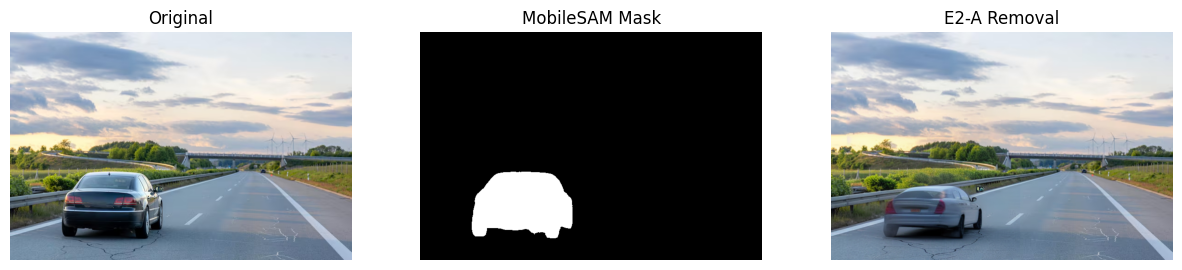

In [37]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(
    cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )
)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("MobileSAM Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(
    cv2.cvtColor(
        output,
        cv2.COLOR_BGR2RGB
    )
)
plt.title("E2-A Removal")
plt.axis("off")

plt.show()

In [38]:
image = cv2.imread(
    BASE_DIR + "car_2.jpg"
)

output, mask, meta = e2a_replace(
    image,
    "Replace the car with a bicycle",
    num_steps=10
)

print(json.dumps(
    meta,
    indent=2
))

{
  "action": "replace",
  "source": "car",
  "target": "bicycle",
  "bbox": [
    111.24042510986328,
    300.8669128417969,
    332.6834716796875,
    446.97869873046875
  ],
  "yolo_confidence": 0.9326183199882507,
  "mobile_sam_score": 0.9966609477996826,
  "detection_time_sec": 0.17687082500015094,
  "segmentation_time_sec": 3.6905308320001495,
  "diffusion_time_sec": 323.29716397899983,
  "total_time_sec": 327.16456563600013,
  "num_steps": 10
}


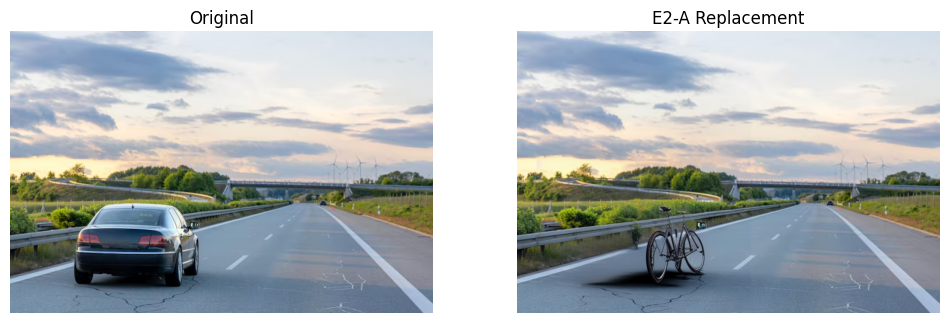

In [39]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.imshow(
    cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("Original")
plt.axis("off")


plt.subplot(1, 2, 2)

plt.imshow(
    cv2.cvtColor(
        output,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("E2-A Replacement")
plt.axis("off")

plt.show()

In [ ]:
image = cv2.imread(
    BASE_DIR + "cat.jpg"
)

output, mask, meta = e2a_remove(
    image,
    "Remove the cat",
    num_steps=10
)

print(json.dumps(
    meta,
    indent=2
))

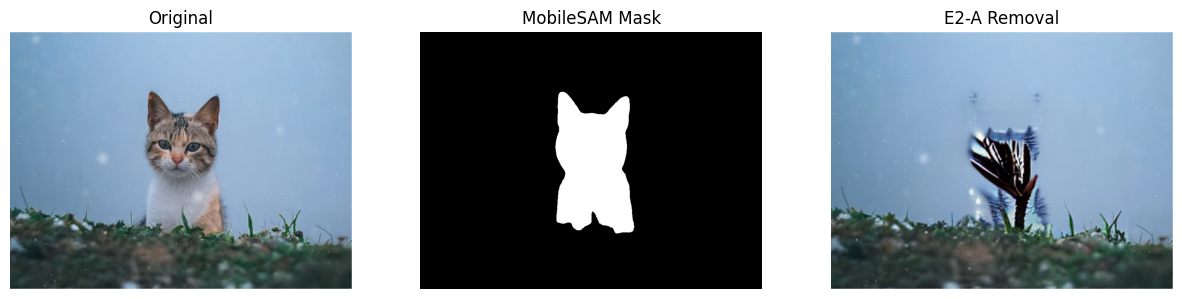

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(
    cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )
)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("MobileSAM Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(
    cv2.cvtColor(
        output,
        cv2.COLOR_BGR2RGB
    )
)
plt.title("E2-A Removal")
plt.axis("off")

plt.show()

In [ ]:
image = cv2.imread(
    BASE_DIR + "cat.jpg"
)

output, mask, meta = e2a_replace(
    image,
    "Replace the cat with a dog",
    num_steps=10
)

print(json.dumps(
    meta,
    indent=2
))

{
  "action": "replace",
  "source": "cat",
  "target": "dog",
  "bbox": [
    366.1806945800781,
    161.94810485839844,
    590.8444213867188,
    558.72021484375
  ],
  "yolo_confidence": 0.8639680743217468,
  "mobile_sam_score": 0.9972254037857056,
  "detection_time_sec": 0.17820537999978114,
  "segmentation_time_sec": 3.3422649730000558,
  "diffusion_time_sec": 101.59632673400029,
  "total_time_sec": 105.11679708700012,
  "num_steps": 10
}


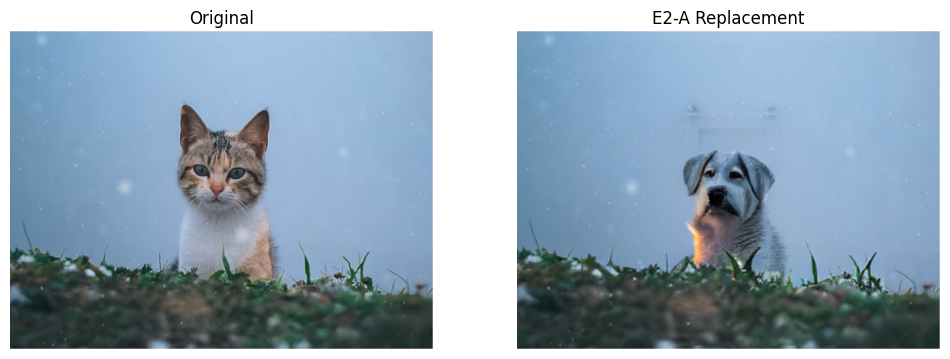

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.imshow(
    cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("Original")
plt.axis("off")


plt.subplot(1, 2, 2)

plt.imshow(
    cv2.cvtColor(
        output,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("E2-A Replacement")
plt.axis("off")

plt.show()

In [ ]:
def benchmark_e2(
    benchmark_cases,
    variant="E2-A",
    iterations=3,
    warmup=1,
    num_steps=10,
    save_path=None
):

    rows = []

    if variant == "E2-A":
        replace_fn = e2a_replace
        remove_fn = e2a_remove
        model_size = None

    elif variant == "E2-B":
        replace_fn = e2b_replace
        remove_fn = e2b_remove
        model_size = onnx_size_mb

    else:
        raise ValueError(
            "variant must be E2-A or E2-B"
        )

    for case in benchmark_cases:

        image_path = case["image"]
        instruction = case["instruction"]
        action = case["action"]

        image = cv2.imread(
            image_path
        )

        if image is None:
            print(
                "Skipping:",
                image_path
            )
            continue

        h, w = image.shape[:2]

        fn = (
            replace_fn
            if action == "replace"
            else remove_fn
        )

        print(
            f"\n[{variant}] "
            f"{Path(image_path).name} | "
            f"{instruction}"
        )

        # --------------------------
        # Warmup
        # --------------------------

        for _ in range(warmup):

            try:
                fn(
                    image,
                    instruction,
                    num_steps=num_steps
                )
            except Exception as e:
                print(
                    "Warmup error:",
                    e
                )

        # --------------------------
        # Measured runs
        # --------------------------

        latencies = []

        for i in range(iterations):

            start = time.perf_counter()

            try:

                output, mask, meta = fn(
                    image,
                    instruction,
                    num_steps=num_steps
                )

                elapsed = (
                    time.perf_counter()
                    - start
                )

                latencies.append(
                    elapsed
                )

            except Exception as e:

                print(
                    "Run error:",
                    e
                )

        if not latencies:
            continue

        latencies_ms = (
            np.array(latencies)
            * 1000
        )

        row = {
            "variant": variant,
            "image": Path(
                image_path
            ).name,
            "action": action,
            "instruction": instruction,
            "resolution": f"{w}x{h}",

            "mean_latency_ms":
                float(np.mean(latencies_ms)),

            "median_latency_ms":
                float(np.median(latencies_ms)),

            "std_latency_ms":
                float(np.std(latencies_ms)),

            "min_latency_ms":
                float(np.min(latencies_ms)),

            "max_latency_ms":
                float(np.max(latencies_ms)),

            "diffusion_steps":
                num_steps,

            "model_size_MB":
                model_size
        }

        rows.append(row)

    df = pd.DataFrame(rows)

    if save_path:

        Path(save_path).parent.mkdir(
            parents=True,
            exist_ok=True
        )

        df.to_csv(
            save_path,
            index=False
        )

        print(
            f"\nSaved benchmark to "
            f"{save_path}"
        )

    return df

In [ ]:
benchmark_cases = [
    {
        "image": BASE_DIR + "car_2.jpg",
        "instruction": "Remove the car",
        "operation": "remove"
    },
    {
        "image": BASE_DIR + "park_2.jpg",
        "instruction": "Remove the person",
        "operation": "remove"
    },
    {
        "image": BASE_DIR + "road_2.jpg",
        "instruction": "Remove the bicycle",
        "operation": "remove"
    },
    {
        "image": BASE_DIR + "car.jpg",
        "instruction": "Replace the car with a bicycle",
        "operation": "replace"
    }
]

In [ ]:
e2a_results = benchmark_e2(
    benchmark_cases,
    variant="E2-A",
    iterations=3,
    warmup=1,
    num_steps=10,
    save_path=BASE_DIR + "benchmarks/e2a_benchmark.csv"
)

e2a_results